# Biomass LA2 product Congo basin vs CCI Biomass
Objetive: Get the CCI biomass product that match with the AOI resample it and validate with the Biomass LA2 product

### 1. Packages and Libraries

In [1]:
%pip install aiohttp requests

from shapely.geometry import Polygon, box
from rasterio.windows import Window
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from pystac_client import Client
from folium import GeoJson
import geopandas as gpd
from io import BytesIO
import rasterio as rio
from tqdm import tqdm
from PIL import Image
import pandas as pd
import numpy as np
import requests
import pathlib
import fsspec
import folium
import fiona
import os

fiona.supported_drivers["KML"] = "rw"  # Enable kml driver

from rasterio.windows import from_bounds
from rasterio.plot import show
from rasterio.plot import plotting_extent
from shapely.geometry import shape
from rasterio.enums import Resampling
import rioxarray  # adds .rio to xarray

  Using cached aiohttp-3.14.5-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (8.3 kB)
  Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl.metadata (5.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached frozenlist-1.8.0-cp312-cp312-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (20 kB)
  Using cached multidict-7.1.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (6.2 kB)
  Using cached propcache-0.5.4-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (25 kB)
  Using cached yarl-1.25.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (111 kB)
Using cached aiohttp-3.14.5-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (1.9 MB)
Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl (15 kB)
Using cached aiosignal-1.4.0-py3-none-any.

## 2. Open the DF with the CCI Biomass information available

In [2]:
path_gdf = r'CCI_biomass_products_Congo_valid_pxs.csv'
df = pd.read_csv(path_gdf)
# gdf

In [3]:
path_gdf = r'CCI_biomass_products_Congo.shp'
gdf = gpd.read_file(path_gdf)

In [4]:
idx_max_px = np.argmax(df['Valid_pixels'])
prod_id = gdf.loc[idx_max_px, 'product_id']
item = gdf.loc[idx_max_px, 'item']
minx, miny, maxx, maxy = gdf.loc[idx_max_px,'geometry'].bounds
print(idx_max_px,prod_id, item)
cci_bbox = minx, miny, maxx, maxy

4 N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0 <Item id=N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0>


## 2. Open AGB LA2 Congo map

In [5]:
# Path to your GeoTIFF file
tif_path = f"agbd_map_L2A_cropped_{prod_id}.tif"

with rio.open(tif_path) as src:
    print("File:", src.name)
    print("Raster dimensions:", src.width, "x", src.height)
    print("Number of bands:", src.count)
    print("Coordinate reference system:", src.crs)
    print("Pixel resolution:", src.res)
    print("No-data value:", src.nodata)
    print("Band descriptions:", src.descriptions)
    print("Bounds:", src.bounds)
    # Read the first band, masking no-data pixels
    band_agb = src.read(1, masked=True).astype("float32")

    # Geographic or projected map extent
    extent = plotting_extent(src)
    crs = src.crs

File: agbd_map_L2A_cropped_N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0.tif
Raster dimensions: 5562 x 5529
Number of bands: 1
Coordinate reference system: EPSG:4326
Pixel resolution: (0.0017980138121629352, 0.0018087108088100656)
No-data value: nan
Band descriptions: (None,)
Bounds: BoundingBox(left=19.99930763268833, bottom=1.7763568394002505e-15, right=29.999860455938574, top=10.000362061910854)


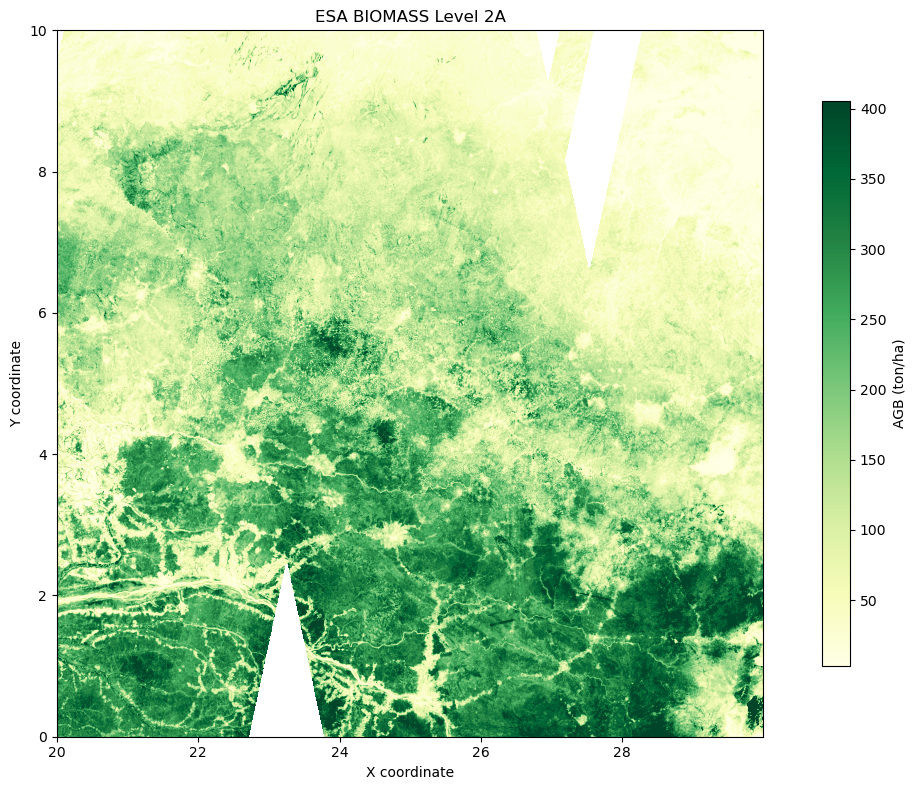

In [6]:
# Convert missing pixels to NaN
band_agb_data = band_agb.filled(np.nan)
band_agb_data[~np.isfinite(band_agb_data)] = np.nan

# Calculate a display range that reduces the influence of extreme values
valid_values = band_agb_data[np.isfinite(band_agb_data)]

if valid_values.size == 0:
    raise ValueError(
        "No valid pixels found. Check the TIFF file and its no-data values."
    )

vmin, vmax = np.percentile(valid_values, [2, 98])

fig, ax = plt.subplots(figsize=(12, 8))

img = ax.imshow(
    band_agb_data,
    extent=extent,
    origin="upper",
    cmap="YlGn",
    vmin=vmin,
    vmax=vmax
)

# Add colorbar and labels
cbar = fig.colorbar(img, ax=ax, shrink=0.8)
cbar.set_label("AGB (ton/ha)")

ax.set_title("ESA BIOMASS Level 2A")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")

plt.tight_layout()
plt.show()

## 3. Query the ESA MAAP STAC catalog

In [7]:
catalog_url = 'https://catalog.maap.eo.esa.int/catalogue/'
catalog = Client.open(catalog_url)

### 3.1.  Select a collection and narrow down the search
Using the bounding box of the AGB map from Congo get the CCI Biomass items

In [8]:
search = catalog.search(
    collections = ["CCIBiomassV5.01"],
    datetime = ['2021-01-01T00:00:00Z','2021-12-31T00:00:00Z'],
    bbox = cci_bbox,
    method = "GET",
    max_items = 50,  
)

items = list(search.items())
print(f"Accessing {len(items)} items (limited by max_items).")
print(f"{search.matched()} items found that matched the query.")

Accessing 18 items (limited by max_items).
18 items found that matched the query.


In [9]:
print(prod_id)
biomass_product = [id_ for id_ in items if prod_id in str(id_)][0]

N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0


In [10]:
# Inspect results 

print(f"Item ID: {biomass_product.id}")
print(f"  - Datetime: {biomass_product.datetime}")
print(f"  - BBOX: {biomass_product.bbox}")
print(f"  - Properties: {biomass_product.properties}")
print("  - Assets:")
for key, asset in biomass_product.assets.items():
    print(f"      • {key}: {asset.href}")
print()

Item ID: N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
  - Datetime: 2021-01-01 00:00:00+00:00
  - BBOX: [20, 0, 30, 10]
  - Properties: {'processing:level': 'L4', 'proj:code': '4326', 'keywords': ['satellite', 'observation', 'forest', 'biomass'], 'start_datetime': '2021-01-01T00:00:00.000Z', 'end_datetime': '2021-12-31T23:59:59.000Z', 'created': '2024-02-19T00:00:00.000Z', 'processing:facility': 'GAMMA Remote Sensing', 'published': '2025-09-25T14:14:38.326Z', 'title': 'N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0', 'osc:project': 'Climate Change Initiative - European Space Agency', 'osc:status': 'completed', 'version': '5.0', 'platform': 'ALOS-2', 'auth:schemes': {'s3': {'type': 's3'}, 'oidc': {'openIdConnectUrl': 'https://iam.ascend.icsgate.eu/realms/esa-maap/.well-known/openid-configuration', 'type': 'openIdConnect'}}, 'datetime': '2021-01-01T00:00:00.000Z', 'osc:type': 'product', 'instruments': ['PALSAR-2', 'SAR-C', 'SAR-C'], 'constellation': 'ALOS-2', 'processing:da

In [11]:
ql_url = biomass_product.assets['quicklook_png'].href
print(f"href of the QL: {ql_url}")

from IPython.display import Image, display
print("\n")
display(Image(url= ql_url))

href of the QL: https://catalog.maap.eo.esa.int/data/biomass-maap-01/CCIBiomassV5.01/2021/01/01/N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0/public/N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0_QL.png




In [12]:
# This is permanently valid, you don't need to change the two lines below.
CLIENT_ID="offline-token"
CLIENT_SECRET="p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE"

**You need to create a .txt file and just paste your token inside**

In [13]:
if pathlib.Path("GB_access_token.txt").exists(): # Put here your .txt file path
  with open("GB_access_token.txt","rt") as f:
    OFFLINE_TOKEN = f.read().strip().replace("\n","")
    url = "https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token"
    data = {
        "client_id": CLIENT_ID,
        "client_secret": CLIENT_SECRET,
        "grant_type": "refresh_token",
        "refresh_token": OFFLINE_TOKEN,
        "scope": "offline_access openid"
    }

    response = requests.post(url, data=data)
    response.raise_for_status()

    response_json = response.json()
    access_token = response_json.get('access_token')
    print("Access token retrieved successfully.")

    if not access_token:
        raise RuntimeError("Failed to retrieve access token from IAM response")

else:
    raise RuntimeError(f"No token file found in {os.getcwd()} !")

Access token retrieved successfully.


In [14]:
# Open the agb map cropped with rioxarray
agb_cropped = rioxarray.open_rasterio(f"agbd_map_L2A_cropped_{prod_id}.tif", masked=True).squeeze().load()
# cut the BIOMASS frame to the ALS tile
agb_bounds = agb_cropped.rio.transform_bounds("EPSG:4326")

In [28]:
agb_bounds

(19.99930763268833,
 1.5543122344752192e-15,
 29.999860455938574,
 10.000362061910854)

## 4. Resample the Biomass LA2 to the CCI biomass resolution

In [15]:
# Create an authenticated HTTPS filesystem for streaming access
fs = fsspec.filesystem("https", headers={"Authorization": f"Bearer {access_token}"})

# Open the remote raster file as a binary stream
with fs.open(biomass_product.assets['enclosure_tif'].href, "rb") as f:
    cci_agb = (rioxarray.open_rasterio(f, masked=True).squeeze().rio.clip_box(*agb_bounds, crs="EPSG:4326").load())
    # cci_agb = (rioxarray.open_rasterio(f, masked=True).squeeze().load())

In [16]:
for name, da in [("Biomass LA2", agb_cropped), ("CCI biomass", cci_agb)]:
    print(f"{name:8s} CRS={da.rio.crs}  res={da.rio.resolution()}  shape={da.shape}  "
          f"range=({float(da.min()):.1f}, {float(da.max()):.1f})")

Biomass LA2 CRS=EPSG:4326  res=(0.0017980138121629352, -0.0018087108088100656)  shape=(5529, 5562)  range=(0.1, 1800.0)
CCI biomass CRS=EPSG:4326  res=(0.000888888888888889, -0.000888888888888889)  shape=(11250, 11250)  range=(0.0, 778.0)


In [20]:
cci_on_agb_mean = cci_agb.rio.reproject_match(agb_cropped, resampling=Resampling.average)
cci_on_agb_max = cci_agb.rio.reproject_match(agb_cropped, resampling=Resampling.max)
valid = agb_cropped.notnull().astype("float32").rio.write_nodata(np.nan)
coverage = valid.rio.reproject_match(agb_cropped, resampling=Resampling.average)

MIN_COVER = 0.8
cmp = pd.DataFrame({
    "CCI_biomass_mean": cci_on_agb_mean.values.ravel(),
    "CCI_biomass_max": cci_on_agb_max.values.ravel(),
    "Biomass_LA2": agb_cropped.values.ravel(),
    "cover": coverage.values.ravel(),
}).dropna()
cmp = cmp[cmp["cover"] >= MIN_COVER]
print(f"Matched BIOMASS pixels with >={MIN_COVER:.0%} CCI biomass coverage: {len(cmp)}")


def stats(y_ref, y_est):
    d = y_est - y_ref
    r = np.corrcoef(y_ref, y_est)[0, 1]
    return {"n": len(d), "bias": d.mean(), "RMSE": np.sqrt((d**2).mean()),
            "rel_RMSE_%": 100 * np.sqrt((d**2).mean()) / y_ref.mean(), "R2": r**2}


pd.DataFrame({k: stats(cmp[k], cmp["Biomass_LA2"]) for k in ["CCI_biomass_mean","CCI_biomass_max"]}).T.round(2)

Matched BIOMASS pixels with >=80% CCI biomass coverage: 29810907


,n,bias,RMSE,rel_RMSE_%,R2
CCI_biomass_mean,29810907.0,-16.47,93.31,54.04,0.64
CCI_biomass_max,29810907.0,-71.15,140.15,61.65,0.62


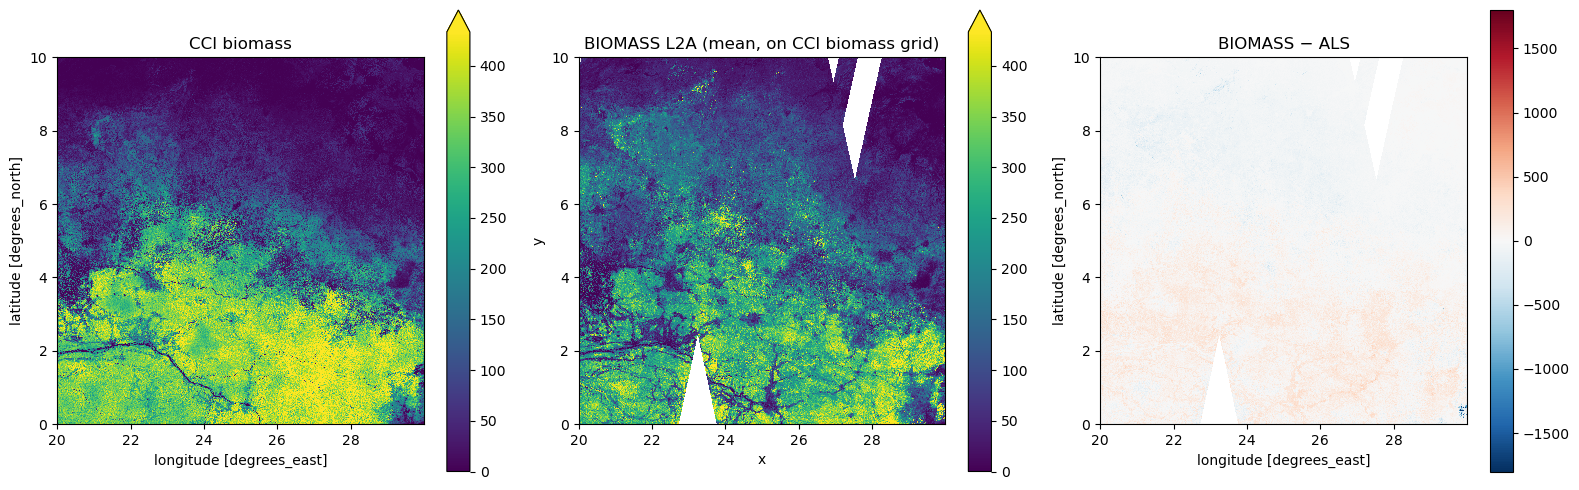

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
vmax = float(np.nanpercentile(agb_cropped, 99))
cci_on_agb_mean.plot(ax=ax[0], vmin=0, vmax=vmax, cmap="viridis"); ax[0].set_title("CCI biomass")
agb_cropped.plot(ax=ax[1], vmin=0, vmax=vmax, cmap="viridis"); ax[1].set_title("BIOMASS L2A (mean, on CCI biomass grid)")
(cci_on_agb_mean - agb_cropped).plot(ax=ax[2], cmap="RdBu_r", center=0); ax[2].set_title("BIOMASS − ALS")
for a in ax:
    a.set_aspect("equal")
plt.tight_layout()
plt.show()

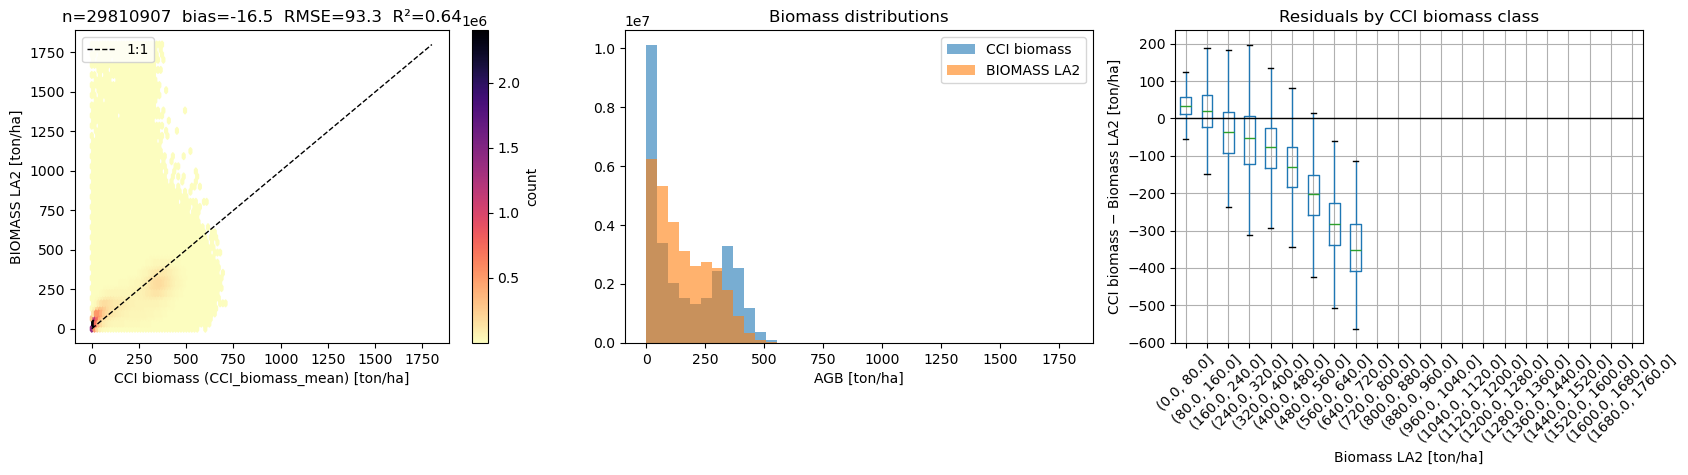

In [27]:
ref = "CCI_biomass_mean"   # switch to "max" to compare
lim = max(cmp[ref].max(), cmp["Biomass_LA2"].max())

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
hb = ax[0].hexbin(cmp[ref], cmp["Biomass_LA2"], gridsize=50, mincnt=1, cmap="magma_r")
ax[0].plot([0, lim], [0, lim], "k--", lw=1, label="1:1")
ax[0].set_xlabel(f"CCI biomass ({ref}) [ton/ha]"); ax[0].set_ylabel("BIOMASS LA2 [ton/ha]")
s = stats(cmp[ref], cmp["Biomass_LA2"])
ax[0].set_title(f"n={s['n']}  bias={s['bias']:.1f}  RMSE={s['RMSE']:.1f}  R²={s['R2']:.2f}")
ax[0].legend(); plt.colorbar(hb, ax=ax[0], label="count")

bins = np.linspace(0, lim, 40)
ax[1].hist(cmp[ref], bins=bins, alpha=0.6, label="CCI biomass")
ax[1].hist(cmp["Biomass_LA2"], bins=bins, alpha=0.6, label="BIOMASS LA2")
ax[1].set_xlabel("AGB [ton/ha]"); ax[1].set_title("Biomass distributions"); ax[1].legend()

# residuals per ALS height class -> saturation in tall forest / overestimation in low forest?
cmp["cci_biomass_class"] = pd.cut(cmp[ref], bins=np.arange(0, lim + 5, 80))
cmp["resid"] = cmp["Biomass_LA2"] - cmp[ref]
cmp.boxplot(column="resid", by="cci_biomass_class", ax=ax[2], rot=45, showfliers=False)
ax[2].axhline(0, color="k", lw=1)
ax[2].set_xlabel("Biomass LA2 [ton/ha]"); ax[2].set_ylabel("CCI biomass − Biomass LA2 [ton/ha]")
ax[2].set_title("Residuals by CCI biomass class"); fig.suptitle("")
plt.tight_layout()
plt.show()